# Movement Bout Velocity Statistics

Compute velocity statistics of movement bouts from reference motion data.

**Pipeline:**
1. Compute instantaneous speed from (x,y) global coordinates at 50Hz
2. Smooth with 5-frame (100ms) uniform moving average
3. Threshold at 0.09 m/s to detect "moving" frames
4. Detect contiguous bouts
5. Merge bouts separated by < 5 frames (100ms)
6. Split at local minima that dip > 20% below neighboring peaks
7. Filter out bouts shorter than 25 frames (0.5s)
8. Extract 10-frame (200ms) peak window centered on peak speed
9. Remove ramp frames (>20% speed change between consecutive frames)
10. Compute mean of trimmed peak window and peak speed of full bout

In [1]:
import csv
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks

%matplotlib inline

In [2]:
DATA_PATH = "../../data/rodent/rodent_reference_clips.h5"
N_CLIPS = 842
FRAMES_PER_CLIP = 250
DT = 0.02  # 50 Hz

# Pipeline parameters
SMOOTH_WINDOW = 5  # frames (100ms)
SPEED_THRESH = 0.09  # m/s
MERGE_GAP = 5  # frames (100ms)
MIN_BOUT_FRAMES = 25  # 0.5s
MIN_DEPTH_FRAC = 0.2  # 20% dip to split
PEAK_WINDOW = 10  # frames (200ms)
RAMP_FRAC = 0.2  # 20% frame-to-frame change

In [3]:
# Load data and compute instantaneous speed
with h5py.File(DATA_PATH, "r") as f:
    qpos = f["qpos"][:]
qpos = qpos.reshape(N_CLIPS, FRAMES_PER_CLIP, -1)
xy = qpos[:, :, :2]
vel = np.diff(xy, axis=1) / DT
speed = np.linalg.norm(vel, axis=2)  # (842, 249)
print(f"Loaded {N_CLIPS} clips, speed shape: {speed.shape}")

Loaded 842 clips, speed shape: (842, 249)


In [4]:
# Process bouts
rows = []
for ci in range(N_CLIPS):
    raw_speed = speed[ci]
    s = uniform_filter1d(raw_speed, size=SMOOTH_WINDOW)

    # Threshold
    moving = s > SPEED_THRESH
    padded = np.concatenate([[False], moving, [False]])
    d = np.diff(padded.astype(int))
    starts = list(np.where(d == 1)[0])
    ends = list(np.where(d == -1)[0])

    # Merge short gaps
    merged_starts, merged_ends = [], []
    for st, en in zip(starts, ends):
        if merged_ends and (st - merged_ends[-1]) < MERGE_GAP:
            merged_ends[-1] = en
        else:
            merged_starts.append(st)
            merged_ends.append(en)

    # Split at local minima and extract peak windows
    for st, en in zip(merged_starts, merged_ends):
        bout_speed = s[st:en]
        if len(bout_speed) < MIN_BOUT_FRAMES:
            continue

        minima, _ = find_peaks(-bout_speed, distance=max(MIN_BOUT_FRAMES // 2, 2))
        if len(minima) == 0:
            sub_bouts = [(st, en)]
        else:
            split_points = [0]
            for m in minima:
                left_peak = bout_speed[:m].max() if m > 0 else bout_speed[m]
                right_peak = (
                    bout_speed[m:].max() if m < len(bout_speed) - 1 else bout_speed[m]
                )
                neighbor_peak = min(left_peak, right_peak)
                depth = (neighbor_peak - bout_speed[m]) / neighbor_peak
                if depth > MIN_DEPTH_FRAC:
                    split_points.append(m)
            split_points.append(len(bout_speed))
            sub_bouts = [
                (st + split_points[i], st + split_points[i + 1])
                for i in range(len(split_points) - 1)
            ]

        for abs_st, abs_en in sub_bouts:
            if abs_en - abs_st < MIN_BOUT_FRAMES:
                continue
            raw_bout = raw_speed[abs_st:abs_en]

            # 10-frame peak window
            peak_idx = np.argmax(raw_bout)
            half_w = PEAK_WINDOW // 2
            win_st = max(0, peak_idx - half_w)
            win_en = min(len(raw_bout), peak_idx + half_w)
            window = raw_bout[win_st:win_en]

            # Remove ramp-up frames from start
            trim_st = 0
            for i in range(len(window) - 1):
                if (
                    window[i] > 0
                    and (window[i + 1] - window[i]) / window[i] > RAMP_FRAC
                ):
                    trim_st = i + 1
                else:
                    break

            # Remove ramp-down frames from end
            trim_en = len(window)
            for i in range(len(window) - 1, 0, -1):
                if (
                    window[i] > 0
                    and (window[i - 1] - window[i]) / window[i] > RAMP_FRAC
                ):
                    trim_en = i
                else:
                    break

            trimmed = window[trim_st:trim_en]
            if len(trimmed) < 2:
                continue

            rows.append(
                [
                    ci,
                    abs_st,
                    abs_en,
                    (abs_en - abs_st) * DT,
                    trimmed.mean(),
                    raw_bout.max(),
                    len(trimmed),
                ]
            )

bout_mean_speeds = np.array([r[4] for r in rows])
bout_peak_speeds = np.array([r[5] for r in rows])
bout_durations = np.array([r[3] for r in rows])
print(f"Total bouts: {len(rows)}")

Total bouts: 554


In [5]:
# Print stats
print(f"=== Movement Bout Statistics ===")
print(
    f"Pipeline: smooth({SMOOTH_WINDOW}f) -> thresh({SPEED_THRESH}m/s) -> "
    f"merge({MERGE_GAP}f) -> split({MIN_DEPTH_FRAC:.0%}) -> "
    f"filter({MIN_BOUT_FRAMES}f) -> peak_window({PEAK_WINDOW}f) -> "
    f"ramp_removal({RAMP_FRAC:.0%})"
)
print(f"Total bouts: {len(rows)}")
print()

for name, arr, u in [
    ("Mean peak window speed", bout_mean_speeds, "m/s"),
    ("Peak speed", bout_peak_speeds, "m/s"),
    ("Duration", bout_durations, "s"),
]:
    pcts = np.percentile(arr, [5, 25, 50, 75, 95])
    print(f"  {name}:")
    print(f"    mean={arr.mean():.4f} {u}, std={arr.std():.4f} {u}")
    print(f"    median={pcts[2]:.4f} {u}")
    print(f"    min={arr.min():.4f} {u}, max={arr.max():.4f} {u}")
    print(
        f"    percentiles: "
        + ", ".join(
            f"p{p}={v:.4f} {u}" for p, v in zip([5, 25, 75, 95], pcts[[0, 1, 3, 4]])
        )
    )
    print()

=== Movement Bout Statistics ===
Pipeline: smooth(5f) -> thresh(0.09m/s) -> merge(5f) -> split(20%) -> filter(25f) -> peak_window(10f) -> ramp_removal(20%)
Total bouts: 554

  Mean peak window speed:
    mean=0.3595 m/s, std=0.1345 m/s
    median=0.3452 m/s
    min=0.1125 m/s, max=0.8029 m/s
    percentiles: p5=0.1706 m/s, p25=0.2533 m/s, p75=0.4498 m/s, p95=0.6079 m/s

  Peak speed:
    mean=0.5309 m/s, std=0.2045 m/s
    median=0.5070 m/s
    min=0.1710 m/s, max=1.2987 m/s
    percentiles: p5=0.2441 m/s, p25=0.3747 m/s, p75=0.6598 m/s, p95=0.9166 m/s

  Duration:
    mean=0.6851 s, std=0.1966 s
    median=0.6200 s
    min=0.5000 s, max=2.3000 s
    percentiles: p5=0.5000 s, p25=0.5400 s, p75=0.7800 s, p95=1.0400 s



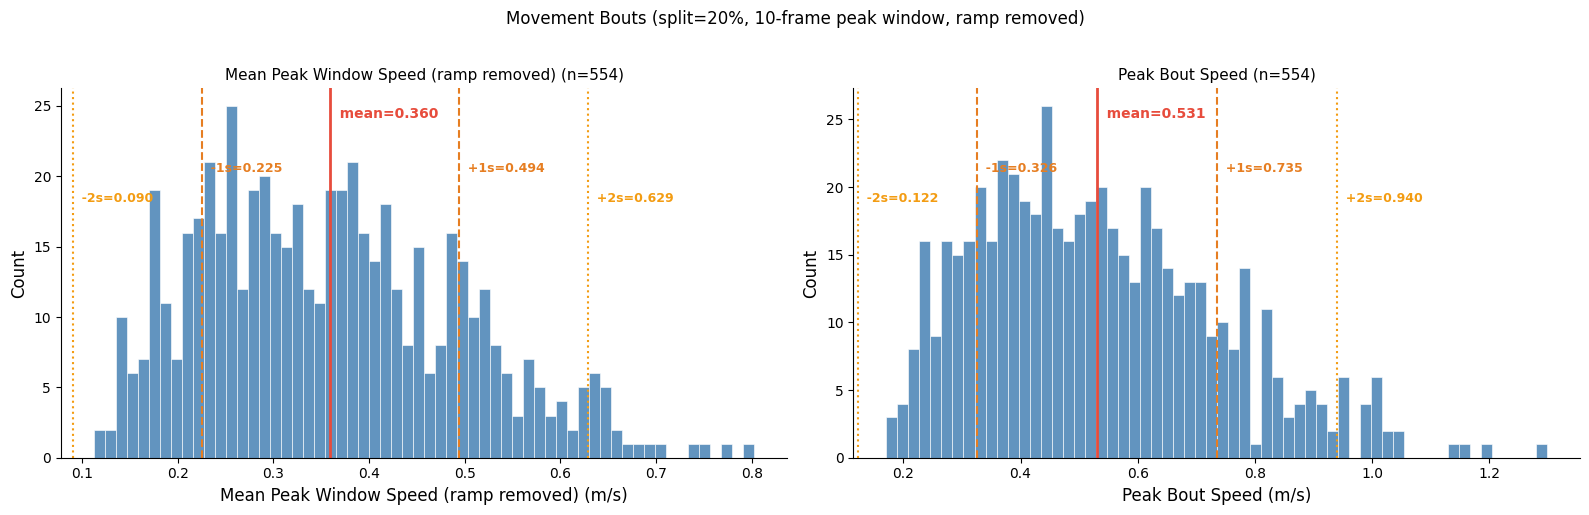

In [6]:
# Plot distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, data, label in [
    (axes[0], bout_mean_speeds, "Mean Peak Window Speed (ramp removed)"),
    (axes[1], bout_peak_speeds, "Peak Bout Speed"),
]:
    mu, sigma = data.mean(), data.std()
    ax.hist(
        data, bins=60, color="steelblue", edgecolor="white", linewidth=0.5, alpha=0.85
    )
    ax.axvline(mu, color="#e74c3c", linewidth=2)
    ax.text(
        mu,
        ax.get_ylim()[1] * 0.95,
        f"  mean={mu:.3f}",
        color="#e74c3c",
        fontsize=10,
        fontweight="bold",
        va="top",
    )
    for sign, pfx in [(1, "+"), (-1, "-")]:
        for n in [1, 2]:
            val = mu + sign * n * sigma
            if val > 0:
                c = "#e67e22" if n == 1 else "#f39c12"
                ls = "--" if n == 1 else ":"
                ax.axvline(val, color=c, linewidth=1.5, linestyle=ls)
                ax.text(
                    val,
                    ax.get_ylim()[1] * (0.88 - 0.08 * n),
                    f"  {pfx}{n}s={val:.3f}",
                    color=c,
                    fontsize=9,
                    fontweight="bold",
                    va="top",
                )
    ax.set_xlabel(f"{label} (m/s)", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    ax.set_title(f"{label} (n={len(data)})", fontsize=11)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Movement Bouts (split=20%, 10-frame peak window, ramp removed)",
    fontsize=12,
    y=1.02,
)
plt.tight_layout()
plt.show()

In [ ]:
# Save CSV
save_dir = Path("../../data/maintain_velocity_analysis")
save_dir.mkdir(parents=True, exist_ok=True)
csv_path = save_dir / "movement_bout_data.csv"

with open(csv_path, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(
        [
            "clip_idx",
            "start_frame",
            "end_frame",
            "duration_s",
            "mean_peak_window_speed_ms",
            "peak_speed_ms",
            "trimmed_window_frames",
        ]
    )
    w.writerows(rows)
print(f"Saved {len(rows)} bouts to {csv_path}")

## Render clip with max peak bout speed

In [7]:
import os

os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import mediapy as media
import mujoco

from vnl_playground.tasks.rodent import consts as rodent_consts

# Find the bout with max peak speed
max_bout_idx = int(np.argmax(bout_peak_speeds))
max_bout = rows[max_bout_idx]
clip_idx = int(max_bout[0])
bout_start = int(max_bout[1])
bout_end = int(max_bout[2])
peak_speed_val = max_bout[5]

print(f"Max peak bout speed: {peak_speed_val:.4f} m/s")
print(f"Clip index: {clip_idx}, frames {bout_start}-{bout_end}")

Max peak bout speed: 1.2987 m/s
Clip index: 15, frames 84-167


In [8]:
# Build MuJoCo model and render the full clip as video
arena_xml = str(rodent_consts.ARENA_XML_PATH)
walker_xml = str(rodent_consts.RODENT_XML_PATH)

arena_spec = mujoco.MjSpec.from_file(arena_xml)
rodent_spec = mujoco.MjSpec.from_file(walker_xml)
frame = arena_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
body = frame.attach_body(rodent_spec.body("walker"), "", suffix="-rodent")
body.add_freejoint(name="root")

# Add overhead light
light = arena_spec.worldbody.add_light(name="overhead")
light.pos = [0, 0, 10]
light.dir = [0, 0, -1]
light.type = mujoco.mjtLightType.mjLIGHT_DIRECTIONAL
light.diffuse = [1.0, 1.0, 1.0]
light.specular = [0.3, 0.3, 0.3]

model = arena_spec.compile()
data = mujoco.MjData(model)

# Get clip qpos (already loaded and reshaped in cell-3)
clip_qpos = qpos[clip_idx]  # (250, 74)

# Render all 250 frames
RENDER_HEIGHT = 480
RENDER_WIDTH = 640
RENDER_FPS = 50
camera = "close_profile-rodent"
cam_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_CAMERA, camera)

renderer = mujoco.Renderer(model, height=RENDER_HEIGHT, width=RENDER_WIDTH)
video_frames = []
for t in range(FRAMES_PER_CLIP):
    data.qpos[:] = clip_qpos[t]
    mujoco.mj_forward(model, data)
    renderer.update_scene(data, camera=cam_id)
    video_frames.append(renderer.render().copy())
renderer.close()

print(f"Rendered clip {clip_idx}: {len(video_frames)} frames")
print(
    f"Bout with max peak speed at frames {bout_start}-{bout_end} "
    f"(peak={peak_speed_val:.3f} m/s)"
)
media.show_video(video_frames, fps=RENDER_FPS)

Rendered clip 15: 250 frames
Bout with max peak speed at frames 84-167 (peak=1.299 m/s)


This browser does not support the video tag.


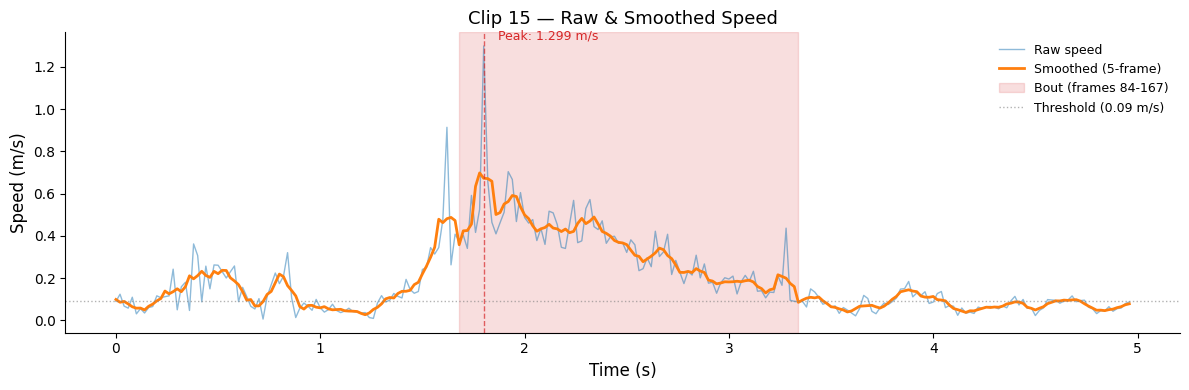

In [9]:
# Plot raw and smoothed speed for the full clip
raw_speed_clip = speed[clip_idx]  # (249,)
smoothed_speed_clip = uniform_filter1d(raw_speed_clip, size=SMOOTH_WINDOW)
time_axis = np.arange(len(raw_speed_clip)) * DT  # seconds

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_axis, raw_speed_clip, alpha=0.5, linewidth=1, label="Raw speed")
ax.plot(
    time_axis,
    smoothed_speed_clip,
    linewidth=2,
    label=f"Smoothed ({SMOOTH_WINDOW}-frame)",
)

# Highlight the bout region
ax.axvspan(
    bout_start * DT,
    bout_end * DT,
    alpha=0.15,
    color="tab:red",
    label=f"Bout (frames {bout_start}-{bout_end})",
)

# Mark peak speed
peak_frame = bout_start + np.argmax(raw_speed_clip[bout_start:bout_end])
ax.axvline(peak_frame * DT, color="tab:red", linestyle="--", linewidth=1, alpha=0.7)
ax.annotate(
    f"Peak: {peak_speed_val:.3f} m/s",
    xy=(peak_frame * DT, peak_speed_val),
    xytext=(10, 5),
    textcoords="offset points",
    fontsize=9,
    color="tab:red",
)

# Threshold line
ax.axhline(
    SPEED_THRESH,
    color="gray",
    linestyle=":",
    linewidth=1,
    alpha=0.6,
    label=f"Threshold ({SPEED_THRESH} m/s)",
)

ax.set_xlabel("Time (s)", fontsize=12)
ax.set_ylabel("Speed (m/s)", fontsize=12)
ax.set_title(f"Clip {clip_idx} — Raw & Smoothed Speed", fontsize=13)
ax.legend(fontsize=9, frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

In [10]:
# Encoder-decoder rollout velocity statistics
# Same pipeline as above, applied to encoder-decoder rollout qpos

ROLLOUT_PATH = "../../data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips_latents.h5"

with h5py.File(ROLLOUT_PATH, "r") as f:
    rollout_qpos = f["encoder_decoder_qpos"][:]  # (842, 490, 74)

N_ROLLOUT_CLIPS = rollout_qpos.shape[0]
FRAMES_PER_ROLLOUT = rollout_qpos.shape[1]

# Compute instantaneous speed from (x, y) positions
rollout_xy = rollout_qpos[:, :, :2]
rollout_vel = np.diff(rollout_xy, axis=1) / DT
rollout_speed = np.linalg.norm(rollout_vel, axis=2)  # (842, 489)
print(
    f"Loaded {N_ROLLOUT_CLIPS} encoder-decoder rollouts, speed shape: {rollout_speed.shape}"
)

Loaded 842 encoder-decoder rollouts, speed shape: (842, 489)


In [11]:
# Process bouts for encoder-decoder rollouts (same pipeline as reference data)
rollout_rows = []
for ci in range(N_ROLLOUT_CLIPS):
    raw_speed = rollout_speed[ci]
    s = uniform_filter1d(raw_speed, size=SMOOTH_WINDOW)

    # Threshold
    moving = s > SPEED_THRESH
    padded = np.concatenate([[False], moving, [False]])
    d = np.diff(padded.astype(int))
    starts = list(np.where(d == 1)[0])
    ends = list(np.where(d == -1)[0])

    # Merge short gaps
    merged_starts, merged_ends = [], []
    for st, en in zip(starts, ends):
        if merged_ends and (st - merged_ends[-1]) < MERGE_GAP:
            merged_ends[-1] = en
        else:
            merged_starts.append(st)
            merged_ends.append(en)

    # Split at local minima and extract peak windows
    for st, en in zip(merged_starts, merged_ends):
        bout_speed = s[st:en]
        if len(bout_speed) < MIN_BOUT_FRAMES:
            continue

        minima, _ = find_peaks(-bout_speed, distance=max(MIN_BOUT_FRAMES // 2, 2))
        if len(minima) == 0:
            sub_bouts = [(st, en)]
        else:
            split_points = [0]
            for m in minima:
                left_peak = bout_speed[:m].max() if m > 0 else bout_speed[m]
                right_peak = (
                    bout_speed[m:].max() if m < len(bout_speed) - 1 else bout_speed[m]
                )
                neighbor_peak = min(left_peak, right_peak)
                depth = (neighbor_peak - bout_speed[m]) / neighbor_peak
                if depth > MIN_DEPTH_FRAC:
                    split_points.append(m)
            split_points.append(len(bout_speed))
            sub_bouts = [
                (st + split_points[i], st + split_points[i + 1])
                for i in range(len(split_points) - 1)
            ]

        for abs_st, abs_en in sub_bouts:
            if abs_en - abs_st < MIN_BOUT_FRAMES:
                continue
            raw_bout = raw_speed[abs_st:abs_en]

            # 10-frame peak window
            peak_idx = np.argmax(raw_bout)
            half_w = PEAK_WINDOW // 2
            win_st = max(0, peak_idx - half_w)
            win_en = min(len(raw_bout), peak_idx + half_w)
            window = raw_bout[win_st:win_en]

            # Remove ramp-up frames from start
            trim_st = 0
            for i in range(len(window) - 1):
                if (
                    window[i] > 0
                    and (window[i + 1] - window[i]) / window[i] > RAMP_FRAC
                ):
                    trim_st = i + 1
                else:
                    break

            # Remove ramp-down frames from end
            trim_en = len(window)
            for i in range(len(window) - 1, 0, -1):
                if (
                    window[i] > 0
                    and (window[i - 1] - window[i]) / window[i] > RAMP_FRAC
                ):
                    trim_en = i
                else:
                    break

            trimmed = window[trim_st:trim_en]
            if len(trimmed) < 2:
                continue

            rollout_rows.append(
                [
                    ci,
                    abs_st,
                    abs_en,
                    (abs_en - abs_st) * DT,
                    trimmed.mean(),
                    raw_bout.max(),
                    len(trimmed),
                ]
            )

rollout_bout_mean_speeds = np.array([r[4] for r in rollout_rows])
rollout_bout_peak_speeds = np.array([r[5] for r in rollout_rows])
rollout_bout_durations = np.array([r[3] for r in rollout_rows])
print(f"Total encoder-decoder bouts: {len(rollout_rows)}")

Total encoder-decoder bouts: 810


In [12]:
# Print encoder-decoder rollout stats
print(f"=== Encoder-Decoder Rollout Bout Statistics ===")
print(
    f"Pipeline: smooth({SMOOTH_WINDOW}f) -> thresh({SPEED_THRESH}m/s) -> "
    f"merge({MERGE_GAP}f) -> split({MIN_DEPTH_FRAC:.0%}) -> "
    f"filter({MIN_BOUT_FRAMES}f) -> peak_window({PEAK_WINDOW}f) -> "
    f"ramp_removal({RAMP_FRAC:.0%})"
)
print(f"Total bouts: {len(rollout_rows)}")
print()

for name, arr, u in [
    ("Mean peak window speed", rollout_bout_mean_speeds, "m/s"),
    ("Peak speed", rollout_bout_peak_speeds, "m/s"),
    ("Duration", rollout_bout_durations, "s"),
]:
    pcts = np.percentile(arr, [5, 25, 50, 75, 95])
    print(f"  {name}:")
    print(f"    mean={arr.mean():.4f} {u}, std={arr.std():.4f} {u}")
    print(f"    median={pcts[2]:.4f} {u}")
    print(f"    min={arr.min():.4f} {u}, max={arr.max():.4f} {u}")
    print(
        f"    percentiles: "
        + ", ".join(
            f"p{p}={v:.4f} {u}" for p, v in zip([5, 25, 75, 95], pcts[[0, 1, 3, 4]])
        )
    )
    print()

=== Encoder-Decoder Rollout Bout Statistics ===
Pipeline: smooth(5f) -> thresh(0.09m/s) -> merge(5f) -> split(20%) -> filter(25f) -> peak_window(10f) -> ramp_removal(20%)
Total bouts: 810

  Mean peak window speed:
    mean=0.2047 m/s, std=0.0757 m/s
    median=0.1923 m/s
    min=0.0902 m/s, max=0.7245 m/s
    percentiles: p5=0.1118 m/s, p25=0.1497 m/s, p75=0.2503 m/s, p95=0.3259 m/s

  Peak speed:
    mean=0.2796 m/s, std=0.1084 m/s
    median=0.2632 m/s
    min=0.1110 m/s, max=1.2714 m/s
    percentiles: p5=0.1508 m/s, p25=0.2085 m/s, p75=0.3321 m/s, p95=0.4334 m/s

  Duration:
    mean=0.6642 s, std=0.1764 s
    median=0.6200 s
    min=0.5000 s, max=2.0400 s
    percentiles: p5=0.5000 s, p25=0.5400 s, p75=0.7200 s, p95=1.0110 s



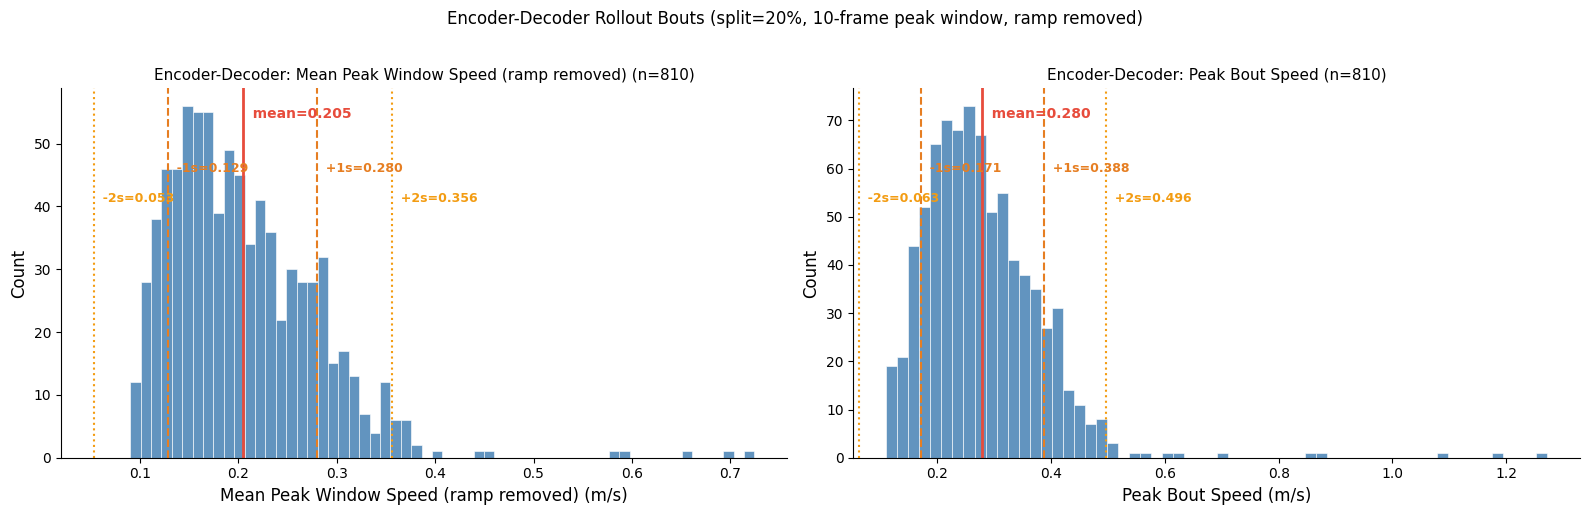

In [13]:
# Plot encoder-decoder rollout distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, data, label in [
    (axes[0], rollout_bout_mean_speeds, "Mean Peak Window Speed (ramp removed)"),
    (axes[1], rollout_bout_peak_speeds, "Peak Bout Speed"),
]:
    mu, sigma = data.mean(), data.std()
    ax.hist(
        data, bins=60, color="steelblue", edgecolor="white", linewidth=0.5, alpha=0.85
    )
    ax.axvline(mu, color="#e74c3c", linewidth=2)
    ax.text(
        mu,
        ax.get_ylim()[1] * 0.95,
        f"  mean={mu:.3f}",
        color="#e74c3c",
        fontsize=10,
        fontweight="bold",
        va="top",
    )
    for sign, pfx in [(1, "+"), (-1, "-")]:
        for n in [1, 2]:
            val = mu + sign * n * sigma
            if val > 0:
                c = "#e67e22" if n == 1 else "#f39c12"
                ls = "--" if n == 1 else ":"
                ax.axvline(val, color=c, linewidth=1.5, linestyle=ls)
                ax.text(
                    val,
                    ax.get_ylim()[1] * (0.88 - 0.08 * n),
                    f"  {pfx}{n}s={val:.3f}",
                    color=c,
                    fontsize=9,
                    fontweight="bold",
                    va="top",
                )
    ax.set_xlabel(f"{label} (m/s)", fontsize=12)
    ax.set_ylabel("Count", fontsize=12)
    ax.set_title(f"Encoder-Decoder: {label} (n={len(data)})", fontsize=11)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Encoder-Decoder Rollout Bouts (split=20%, 10-frame peak window, ramp removed)",
    fontsize=12,
    y=1.02,
)
plt.tight_layout()
plt.show()